<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'iris' dataset.
Path to dataset files: /kaggle/input/iris


In [ ]:
import glob
import os
import pandas as pd

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
df = pd.read_csv(csv_files[0])
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Shape: (150, 6)
Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Data handling
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Load and preprocess the Iris dataset
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# KNN algorithm
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

Step 1: EDA - head() , describe () , groupby()

In [ ]:
#First Five Rows
display(df.head())

print("Summary:")
print("The dataset contains flower measurements and their species labels.")
print("The first five records show sepal and petal dimensions in centimeters.")
print("The Species column identifies the type of Iris flower.")
print("These rows give us an initial view of the dataset structure.")

#Statistical Description
display(df.describe())

print("Summary:")
print("The dataset contains 150 records.")
print("The mean represents the average value of each numerical column.")
print("Standard deviation indicates how much the measurements vary.")
print("Minimum, maximum, and quartiles help us understand data distribution.")

#Number of Samples in Each Species
print("\n3. Number of Samples in Each Species:")
print(df.groupby('Species').size())

print("Summary:")
print("The dataset contains three Iris species.")
print("Each species has 50 flower samples.")
print("The classes are equally represented in the dataset.")
print("This provides a balanced dataset for classification.")

#Dataset Information
print("\n4. Dataset Information:")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Column names:", df.columns.tolist())

print("Summary:")
print("The dataset contains 150 rows and 6 columns.")
print("Four columns contain flower measurements.")
print("The Id column identifies individual records.")
print("The Species column contains the target class for prediction.")

#Missing Values
print("\n5. Missing Values in Each Column:")
print(df.isnull().sum())

print("Summary:")
print("Missing values are checked in every column.")
print("A value of zero means that the column has no missing entries.")
print("Missing data can affect model training and accuracy.")
print("The results help determine whether data cleaning is required.")

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Summary:
The dataset contains flower measurements and their species labels.
The first five records show sepal and petal dimensions in centimeters.
The Species column identifies the type of Iris flower.
These rows give us an initial view of the dataset structure.


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Summary:
The dataset contains 150 records.
The mean represents the average value of each numerical column.
Standard deviation indicates how much the measurements vary.
Minimum, maximum, and quartiles help us understand data distribution.

3. Number of Samples in Each Species:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64
Summary:
The dataset contains three Iris species.
Each species has 50 flower samples.
The classes are equally represented in the dataset.
This provides a balanced dataset for classification.

4. Dataset Information:
Total rows: 150
Total columns: 6
Column names: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Summary:
The dataset contains 150 rows and 6 columns.
Four columns contain flower measurements.
The Id column identifies individual records.
The Species column contains the target class for prediction.

5. Missing Values in Each Column:
Id               0
SepalLengthCm    0
SepalWidthCm  

Step 2: Feature scaling

In [ ]:
# Separate input features and target
X = df.drop(columns=['Id', 'Species'])
y = df['Species']

print("\n1. Separating Features and Target")
print("Feature columns:", X.columns.tolist())
print("Target column:", y.name)
print("Number of feature records:", X.shape[0])
print("Number of target records:", y.shape[0])

print("\nSummary:")
print("Four flower measurements are selected as input features.")
print("Species is selected as the target for classification.")
print("The Id column is excluded because it is only a record identifier.")

#Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n2. Training and Testing Split")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nSummary:")
print("80% of the data is used for training the KNN model.")
print("20% of the data is reserved for testing model performance.")
print("Stratification maintains the species proportions in both sets.")
print("random_state=42 makes the split reproducible.")

# Apply feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n3. Feature Scaling Results")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nSummary:")
print("StandardScaler transforms features to a common scale.")
print("Training data is used to calculate the scaling parameters.")
print("The same parameters are applied to the testing data.")
print("Scaling is important because KNN uses distances between samples.")


1. Separating Features and Target
Feature columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Target column: Species
Number of feature records: 150
Number of target records: 150

Summary:
Four flower measurements are selected as input features.
Species is selected as the target for classification.
The Id column is excluded because it is only a record identifier.

2. Training and Testing Split
Training samples: 120
Testing samples: 30

Summary:
80% of the data is used for training the KNN model.
20% of the data is reserved for testing model performance.
Stratification maintains the species proportions in both sets.
random_state=42 makes the split reproducible.

3. Feature Scaling Results
Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)

Summary:
StandardScaler transforms features to a common scale.
Training data is used to calculate the scaling parameters.
The same parameters are applied to the testing data.
Scaling is important because KN

Step 3: Training the K-NN model on the Training set

In [ ]:
# Create the KNN classifier
k = 5
knn = KNeighborsClassifier(n_neighbors=k)

print("\n1. Initializing the KNN Classifier")
print("Value of K:", k)
print("Algorithm: K-Nearest Neighbors")

print("\nSummary:")
print("It classifies a sample using the majority class of its nearest neighbors.")
print("Here, K=5 means the five nearest training samples are considered.")
print("The model uses distances between the scaled flower measurements.")

#Model train
knn.fit(X_train_scaled, y_train)
print("\nSummary:")
print("The model has been fitted using the training dataset.")
print("The scaled measurements are used as input features.")
print("The known species labels are used as target values.")
print("The trained classifier is now ready to predict unseen samples.")


1. Initializing the KNN Classifier
Value of K: 5
Algorithm: K-Nearest Neighbors

Summary:
It classifies a sample using the majority class of its nearest neighbors.
Here, K=5 means the five nearest training samples are considered.
The model uses distances between the scaled flower measurements.

Summary:
The model has been fitted using the training dataset.
The scaled measurements are used as input features.
The known species labels are used as target values.
The trained classifier is now ready to predict unseen samples.


Step 4: Making the Confusion Matrix & Predicting Accuracy Score


1. Model Predictions
Actual species: ['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']
Predicted species: ['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-ve

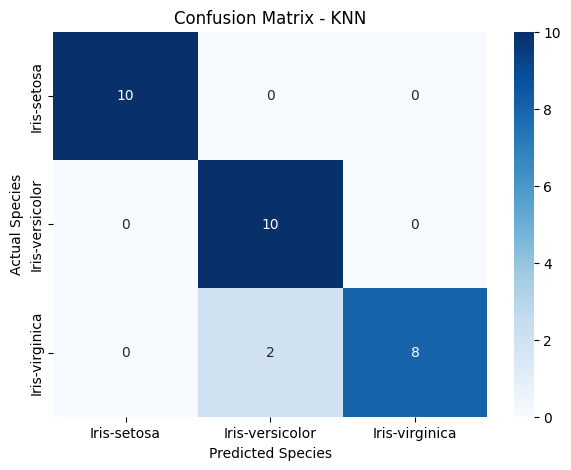

Accuracy Score
Accuracy: 0.9333
Accuracy Percentage: 93.33 %


In [ ]:
#Predict species
y_pred = knn.predict(X_test_scaled)

print("\n1. Model Predictions")
print("Actual species:", y_test.values)
print("Predicted species:", y_pred)

#confusion matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)
# Visualize
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - KNN")
plt.show()
#accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score")#Accuracy=Correct predition/total prediction*100
print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Step 5: Making Classification Report

In [ ]:
print(classification_report(y_test, y_pred, target_names=knn.classes_, digits=3))

# Short summary built from the real results
report = classification_report(y_test, y_pred, target_names=knn.classes_, output_dict=True)
acc = accuracy_score(y_test, y_pred)

best = max(knn.classes_, key=lambda c: report[c]["f1-score"])
worst = min(knn.classes_, key=lambda c: report[c]["f1-score"])

print(f"Accuracy: {acc*100:.1f}% on {len(y_test)} test samples")
print(f"Best classified : {best} (F1 = {report[best]['f1-score']:.2f})")
print(f"Weakest class   : {worst} (F1 = {report[worst]['f1-score']:.2f})")

if acc == 1.0:
    print("Perfect score: every test flower was classified correctly.")
else:
    print(f"{worst} is where most mistakes happen, so check the confusion matrix for what it gets mixed up with.")

                 precision    recall  f1-score   support

    Iris-setosa      1.000     1.000     1.000        10
Iris-versicolor      0.833     1.000     0.909        10
 Iris-virginica      1.000     0.800     0.889        10

       accuracy                          0.933        30
      macro avg      0.944     0.933     0.933        30
   weighted avg      0.944     0.933     0.933        30

Accuracy: 93.3% on 30 test samples
Best classified : Iris-setosa (F1 = 1.00)
Weakest class   : Iris-virginica (F1 = 0.89)
Iris-virginica is where most mistakes happen, so check the confusion matrix for what it gets mixed up with.


Step 6: Comparing Error Rate with the K Value

In [ ]:
error_rate = []

for k in range(1, 41):
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train, y_train)
    pred_k = knn_k.predict(X_test)
    error_rate.append(np.mean(pred_k != np.array(y_test)))   # fraction of wrong predictions

# Print a compact comparison
print(f"{'K':>3} | {'Error Rate':>10}")
print("-" * 16)
for k, err in enumerate(error_rate, start=1):
    print(f"{k:>3} | {err:>10.4f}")

print(f"\nLowest error: {min(error_rate):.4f} at K = {error_rate.index(min(error_rate)) + 1}")

  K | Error Rate
----------------
  1 |     0.0333
  2 |     0.0667
  3 |     0.0000
  4 |     0.0000
  5 |     0.0000
  6 |     0.0333
  7 |     0.0333
  8 |     0.0333
  9 |     0.0000
 10 |     0.0000
 11 |     0.0333
 12 |     0.0333
 13 |     0.0333
 14 |     0.0333
 15 |     0.0333
 16 |     0.0333
 17 |     0.0333
 18 |     0.0333
 19 |     0.0333
 20 |     0.0667
 21 |     0.0667
 22 |     0.0667
 23 |     0.0333
 24 |     0.0667
 25 |     0.0667
 26 |     0.0667
 27 |     0.0667
 28 |     0.0667
 29 |     0.0667
 30 |     0.0667
 31 |     0.0333
 32 |     0.0667
 33 |     0.0333
 34 |     0.0667
 35 |     0.0667
 36 |     0.0667
 37 |     0.0667
 38 |     0.1000
 39 |     0.0667
 40 |     0.0667

Lowest error: 0.0000 at K = 3


 Step 7: Plot the error values against K values

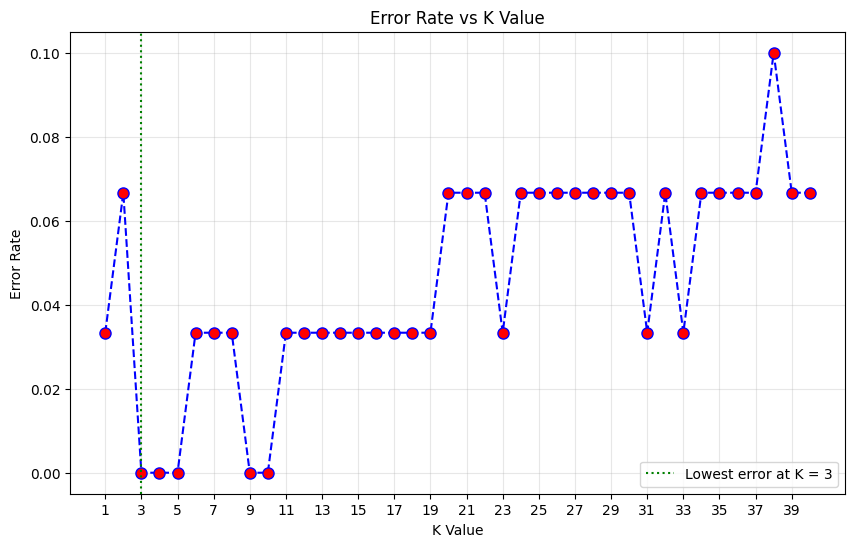

Graph Summary:
- K=1-2: unstable, a single noisy neighbor can change the prediction (overfitting)
- K=3-5 and K=9-10: lowest error (0.00), the best range for this dataset
- K>20: error rises to ~6-10% because too many neighbors blur class boundaries (underfitting)
- Each wrong prediction changes error by ~3.3% (about 30 test samples), so small differences are minor
- Best choice: a small odd K such as 3 or 5


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 41), error_rate, color='blue', linestyle='dashed',
         marker='o', markerfacecolor='red', markersize=8)

# Mark the K with the lowest error
best_k = error_rate.index(min(error_rate)) + 1
plt.axvline(best_k, color='green', linestyle=':', label=f'Lowest error at K = {best_k}')

plt.title('Error Rate vs K Value')
plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.xticks(range(1, 41, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Graph Summary:")
print("- K=1-2: unstable, a single noisy neighbor can change the prediction (overfitting)")
print("- K=3-5 and K=9-10: lowest error (0.00), the best range for this dataset")
print("- K>20: error rises to ~6-10% because too many neighbors blur class boundaries (underfitting)")
print("- Each wrong prediction changes error by ~3.3% (about 30 test samples), so small differences are minor")
print("- Best choice: a small odd K such as 3 or 5")

Step 8: Finding best K

In [ ]:
errors = np.array(error_rate)
k_values = np.arange(1, 41)

min_error = errors.min()
tied_ks = k_values[errors == min_error]
odd_ks = [k for k in tied_ks if k % 2 == 1]      # odd K avoids voting ties

def stability(k):
    window = errors[max(k - 2, 0):k + 1]
    return window.mean()

candidates = odd_ks if odd_ks else list(tied_ks)
best_k = min(candidates, key=stability)

print(f"Lowest error       : {min_error:.4f}")
print(f"K values tied      : {list(tied_ks)}")
print(f"Odd K among them   : {odd_ks}")
print(f"Best K chosen      : {best_k}")

#final model with the best K
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train, y_train)
final_pred = final_knn.predict(X_test)

print(f"\nAccuracy with K={best_k}: {accuracy_score(y_test, final_pred) * 100:.2f}%")

Lowest error       : 0.0000
K values tied      : [np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(10)]
Odd K among them   : [np.int64(3), np.int64(5), np.int64(9)]
Best K chosen      : 5

Accuracy with K=5: 100.00%


Step 9: Visualize Test Result of KNN

2-feature accuracy on test set (K=5): 96.67%


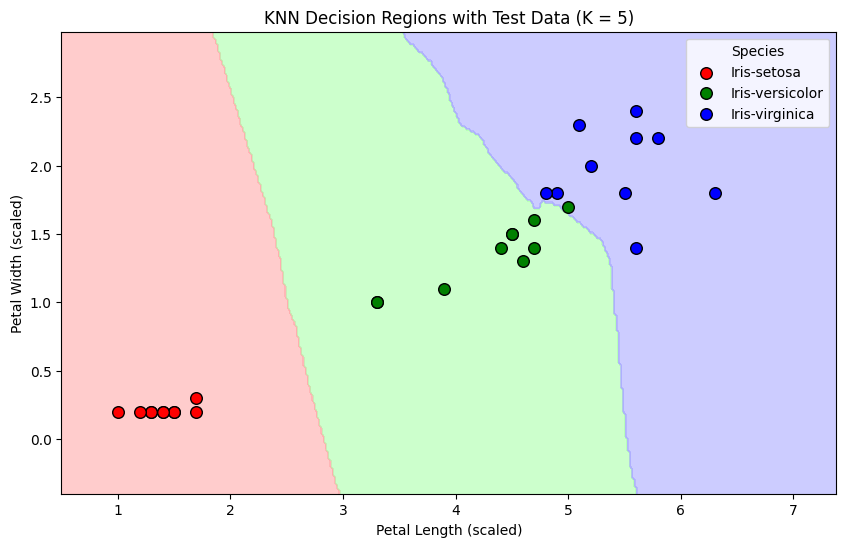

Decision Region Summary (K=5):
1. Setosa is perfectly separated from the other two species
2. Versicolor and virginica overlap near the boundary (petal length ~5-5.5)
3. Almost all test points fall in the correct region, with one virginica near the boundary misclassified
4. K=5 gives a flexible but reasonably smooth boundary
5. Petal length and width alone separate the species well


In [ ]:
f1, f2 = 2, 3                                   # petal length, petal width
Xtr = np.asarray(X_train)[:, [f1, f2]]
Xte = np.asarray(X_test)[:, [f1, f2]]

# Convert string labels to 0/1/2
classes = list(final_knn.classes_)
ytr = np.array([classes.index(c) for c in y_train])
yte = np.array([classes.index(c) for c in y_test])

#2 chosen features only
knn_2d = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, ytr)
print(f"2-feature accuracy on test set (K={best_k}): "
      f"{accuracy_score(yte, knn_2d.predict(Xte)) * 100:.2f}%")

#Building a grid covering the whole plot area
X_all = np.vstack([Xtr, Xte])
x_min, x_max = X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5
y_min, y_max = X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

#Predicting  the class of every grid point these are the decision regions
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

bg_colors   = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
dot_colors  = ['red', 'green', 'blue']

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, cmap=bg_colors, alpha=0.6)

#Ploting the TEST points on top
for i, name in enumerate(classes):
    plt.scatter(Xte[yte == i, 0], Xte[yte == i, 1],
                c=dot_colors[i], edgecolor='k', s=70, label=name)

plt.title(f'KNN Decision Regions with Test Data (K = {best_k})')
plt.xlabel('Petal Length (scaled)')
plt.ylabel('Petal Width (scaled)')
plt.legend(title='Species')
plt.show()
print("Decision Region Summary (K=5):")
print("1. Setosa is perfectly separated from the other two species")
print("2. Versicolor and virginica overlap near the boundary (petal length ~5-5.5)")
print("3. Almost all test points fall in the correct region, with one virginica near the boundary misclassified")
print("4. K=5 gives a flexible but reasonably smooth boundary")
print("5. Petal length and width alone separate the species well")